## This is a notebook working the house price regression problem from Kaggle

### Step 1: Install the necessary packages

In [32]:
!pip install pandas
!pip install numpy
!pip install scikit-learn
!pip install matplotlib
!pip install seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Step 2: Import the necessary packages

In [33]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns


### Step 3: Get the data, print some info about the data and treat missing values

In [34]:
train_df = pd.read_csv('Data/train.csv')
test_df = pd.read_csv('Data/test.csv')

train_df.shape
test_df.shape

train_df.describe()
test_df.describe()

train_null = train_df.isnull().sum().sort_values(ascending=False)
test_null = test_df.isnull().sum().sort_values(ascending=False)

train_df = train_df.loc[:, train_null == 0]
test_df = test_df.dropna(axis=1)
test_df.shape

target_values = train_df[['SalePrice']]
common_cols = train_df.columns.intersection(test_df.columns)

train_df = train_df.loc[:, common_cols]
train_df['SalePrice'] = target_values
test_df = test_df.loc[:, common_cols]


### Step 4: Search for the most correlated values to the target variable 

<Axes: >

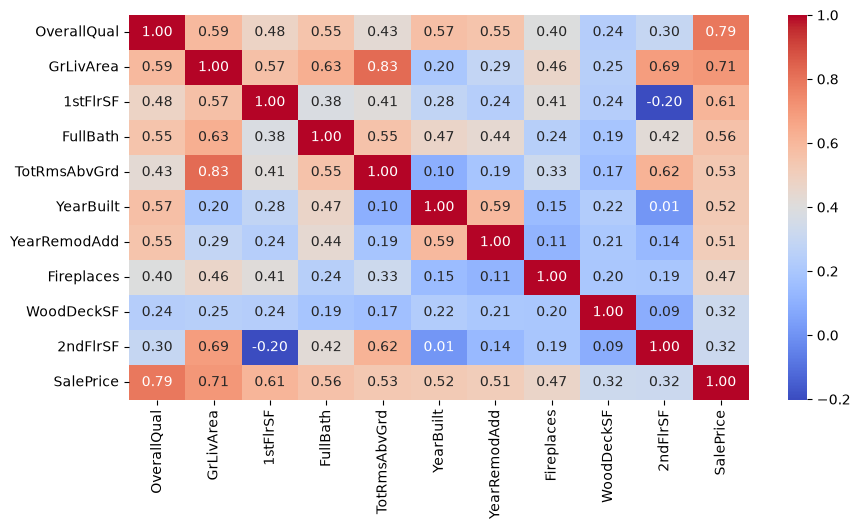

In [35]:
corr = train_df.select_dtypes(include='integer').corr()

top_features = (corr['SalePrice'].drop('SalePrice').abs().nlargest(10).index)

cols = list(top_features) + ['SalePrice']

top_corr = corr.loc[cols, cols]

plt.figure(figsize=(10, 5))
sns.heatmap(top_corr, annot=True, cmap='coolwarm', fmt='.2f')

### Calculate Mutual Information Scores

Both column list contain the same columns


<BarContainer object of 10 artists>

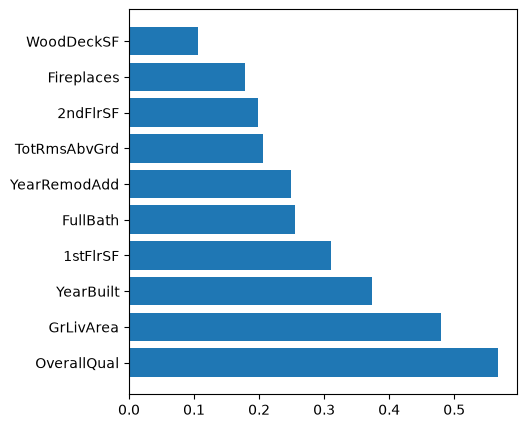

In [36]:
X = train_df[cols].drop(columns='SalePrice').select_dtypes(include='number')
y = train_df['SalePrice']

mi = mutual_info_regression(X, y, random_state=32)
mi_scores = pd.Series(mi, index=X.columns).sort_values(ascending=False).head(10)
mi_cols = list(mi_scores.index)
X_mi = train_df[mi_cols].select_dtypes(include='number')

if sorted(X.columns) == sorted(X_mi.columns):
    print("Both column list contain the same columns")
else:
    print("The column lists do not contain the same columns")


plt.figure(figsize=(5, 5))
plt.barh(mi_scores.index, mi_scores.values)




### Create a regressional model using the variables from the correlation analysis

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=32)

model = make_pipeline(StandardScaler(), LinearRegression())

model.fit(X_train, y_train)

print(f'R squared of the model is: {model.score(X_test, y_test)}')

y_hat = model.predict(X_test)


R squared of the model is: 0.7237786748278534


### Check results

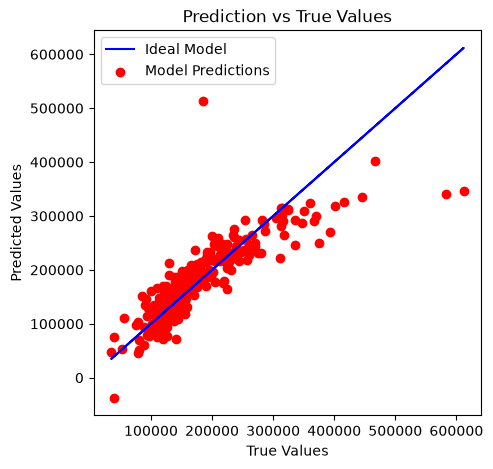

In [38]:
plt.figure(figsize=(5, 5))
plt.plot(y_test, y_test, color='b', label='Ideal Model')
plt.scatter(y_test, y_hat, c='r', label='Model Predictions')
plt.title('Prediction vs True Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()

### Create a polynomial regressional model using the Mutual Information data

In [30]:
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=32)

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

print(f'R squared value: {model.score(X_test, y_test)}')

y_hat = model.predict(X_test)


R squared value: 0.8142556829565897


### Check Results

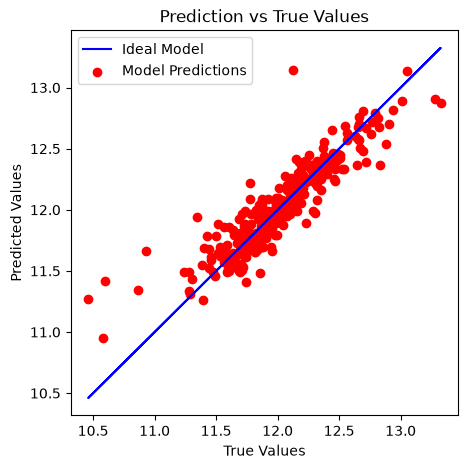

In [31]:
plt.figure(figsize=(5, 5))
plt.plot(y_test, y_test, color='b', label='Ideal Model')
plt.scatter(y_test, y_hat, c='r', label='Model Predictions')
plt.title('Prediction vs True Values')
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.legend()
